# 09 · Optimal scheduling: from merit order to unit commitment with storage
**Level 4 · Decision support (prescriptive)** &nbsp;|&nbsp; Course link: *Module 3 – decision support, optimal scheduling
hands-on: minimise operating cost, then trade cost against emissions*

Forecasts (notebooks 05–06) tell us *what will happen*; optimisation tells us *what to do*. Here a system operator
schedules a small thermal fleet, wind, solar and a battery for one week, hour by hour.

| Pyomo (Python) | MATLAB equivalent |
|---|---|
| `m = pyo.ConcreteModel()` | `prob = optimproblem` |
| `m.p = pyo.Var(G, T, bounds=(0, None))` | `p = optimvar('p', nG, nT, 'LowerBound', 0)` |
| `m.u = pyo.Var(G, T, domain=pyo.Binary)` | `optimvar(..., 'Type', 'integer', 'LowerBound', 0, 'UpperBound', 1)` |
| `m.c = pyo.Constraint(T, rule=...)` | `prob.Constraints.c = ...` |
| `SolverFactory('appsi_highs').solve(m)` | `solve(prob)` (linprog / intlinprog) |
| `m.dual[m.balance[t]]` | `lambda.Constraints.balance` |

The solver is **HiGHS**, an open-source LP/MILP solver.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyomo.environ as pyo
from energy_ai import gb_dataset, clean_load, style
style()

## 1. Inputs: one week of demand, wind and solar
Real Great-Britain profiles (week of 11 March 2019), scaled to a regional system with a 950 MW peak, 450 MW of wind and
300 MW of solar. Renewable availability = capacity × hourly capacity factor.

In [2]:
df = gb_dataset()
load, _ = clean_load(df.load_mw)
wind_all = df.wind_onshore_mw + df.wind_offshore_mw
start = pd.Timestamp("2019-03-11", tz="UTC")
wk = slice(start, start + pd.Timedelta(hours=167))
demand = (load.loc[wk] / load.loc[wk].max() * 950).values
wind = (wind_all.loc[wk] / wind_all.loc["2019"].max() * 450).values
solar = (df.solar_mw.loc[wk] / df.solar_mw.loc["2019"].max() * 300).values
hours = load.loc[wk].index
T = range(len(demand))
print(f"{len(demand)} hours | demand {demand.min():.0f}–{demand.max():.0f} MW | renewable energy available = "
      f"{(wind.sum() + solar.sum()) / demand.sum():.0%} of demand")

fleet = pd.DataFrame([
    # name,     pmax, pmin, fuel €/MWh, CO2 t/MWh, start-up €, min up h, min down h, ramp MW/h
    ("Nuclear",  200, 160, 10,  0.00, 50000, 24, 24,  20),
    ("Coal-1",   150,  60, 32,  0.90,  9000,  8,  8,  60),
    ("Coal-2",   150,  60, 34,  0.92,  9000,  8,  8,  60),
    ("CCGT-1",   120,  50, 48,  0.36,  4000,  4,  3, 100),
    ("CCGT-2",   120,  50, 50,  0.37,  4000,  4,  3, 100),
    ("CCGT-3",   120,  50, 52,  0.38,  4000,  4,  3, 100),
    ("OCGT-1",    50,  10, 105, 0.55,   500,  1,  1,  50),
    ("OCGT-2",    50,  10, 110, 0.56,   500,  1,  1,  50),
    ("OCGT-3",    50,  10, 115, 0.57,   500,  1,  1,  50),
], columns=["name", "pmax", "pmin", "fuel", "co2", "start", "min_up", "min_down", "ramp"]).set_index("name")
initially_on = {"Nuclear", "Coal-1", "CCGT-1"}
VOLL = 3000          # value of lost load [€/MWh]: cost of involuntary load shedding
display(fleet)

168 hours | demand 482–950 MW | renewable energy available = 41% of demand


,pmax,pmin,fuel,co2,start,min_up,min_down,ramp
name,,,,,,,,
Nuclear,200,160,10,0.00,50000,24,24,20
Coal-1,150,60,32,0.90,9000,8,8,60
Coal-2,150,60,34,0.92,9000,8,8,60
CCGT-1,120,50,48,0.36,4000,4,3,100
CCGT-2,120,50,50,0.37,4000,4,3,100
CCGT-3,120,50,52,0.38,4000,4,3,100
OCGT-1,50,10,105,0.55,500,1,1,50
OCGT-2,50,10,110,0.56,500,1,1,50
OCGT-3,50,10,115,0.57,500,1,1,50


## 2. One model, several levels of realism
A single function builds the optimisation problem; switches add realism step by step:

**Economic dispatch (LP)** – choose generator outputs $p_{g,t}$:
$$\min \sum_{g,t} c_g\,p_{g,t} + \text{VoLL}\sum_t s_t \quad\text{s.t.}\quad \sum_g p_{g,t} + w_t + r_t + s_t = D_t\ \ (\lambda_t),\quad 0\le p_{g,t}\le P^{max}_g$$
where $w_t, r_t$ are the wind and solar actually used ($\le$ available, the rest is curtailed) and $s_t$ is shed load.

**Unit commitment (MILP)** – add binaries $u_{g,t}$ (on/off), $v_{g,t}$ (start-up), $z_{g,t}$ (shut-down):
$$u_{g,t}P^{min}_g \le p_{g,t} \le u_{g,t}P^{max}_g,\quad v_{g,t}-z_{g,t}=u_{g,t}-u_{g,t-1},\quad
\sum_{\tau=t-UT_g+1}^{t} v_{g,\tau}\le u_{g,t},\quad \sum_{\tau=t-DT_g+1}^{t} z_{g,\tau}\le 1-u_{g,t}$$
plus ramp limits and start-up costs $\sum S_g v_{g,t}$ in the objective.

**Battery** – charge $c_t$, discharge $d_t$, state of charge $e_t = e_{t-1} + \eta c_t - d_t/\eta$, $0\le e_t\le E$.

**Carbon price / emission cap** – fuel cost becomes $c_g + \pi_{CO_2}\,\text{co2}_g$, or $\sum \text{co2}_g p_{g,t} \le \varepsilon$.

In [3]:
def build(commitment=True, battery=None, carbon_price=0.0, co2_cap=None, objective="cost"):
    m = pyo.ConcreteModel()
    G = list(fleet.index)
    m.p = pyo.Var(G, T, bounds=lambda m, g, t: (0, fleet.pmax[g]))
    m.w = pyo.Var(T, bounds=lambda m, t: (0, wind[t]))
    m.r = pyo.Var(T, bounds=lambda m, t: (0, solar[t]))
    m.shed = pyo.Var(T, bounds=lambda m, t: (0, demand[t]))
    cost_g = {g: fleet.fuel[g] + carbon_price * fleet.co2[g] for g in G}
    m.emis = pyo.Expression(expr=sum(fleet.co2[g] * m.p[g, t] for g in G for t in T))
    oper = sum(cost_g[g] * m.p[g, t] for g in G for t in T) + VOLL * sum(m.shed[t] for t in T)

    if commitment:
        m.u = pyo.Var(G, T, domain=pyo.Binary)
        m.v = pyo.Var(G, T, domain=pyo.Binary)
        m.z = pyo.Var(G, T, domain=pyo.Binary)
        prev = lambda g, t: m.u[g, t - 1] if t > 0 else (1 if g in initially_on else 0)
        m.pmin = pyo.Constraint(G, T, rule=lambda m, g, t: m.p[g, t] >= fleet.pmin[g] * m.u[g, t])
        m.pmax = pyo.Constraint(G, T, rule=lambda m, g, t: m.p[g, t] <= fleet.pmax[g] * m.u[g, t])
        m.logic = pyo.Constraint(G, T, rule=lambda m, g, t: m.v[g, t] - m.z[g, t] == m.u[g, t] - prev(g, t))
        m.min_up = pyo.Constraint(G, T, rule=lambda m, g, t:
                                  sum(m.v[g, k] for k in range(max(0, t - fleet.min_up[g] + 1), t + 1)) <= m.u[g, t])
        m.min_dn = pyo.Constraint(G, T, rule=lambda m, g, t:
                                  sum(m.z[g, k] for k in range(max(0, t - fleet.min_down[g] + 1), t + 1)) <= 1 - m.u[g, t])
        m.ramp_up = pyo.Constraint(G, T, rule=lambda m, g, t: pyo.Constraint.Skip if t == 0 else
                                   m.p[g, t] - m.p[g, t - 1] <= fleet.ramp[g] + fleet.pmin[g] * m.v[g, t])
        m.ramp_dn = pyo.Constraint(G, T, rule=lambda m, g, t: pyo.Constraint.Skip if t == 0 else
                                   m.p[g, t - 1] - m.p[g, t] <= fleet.ramp[g] + fleet.pmin[g] * m.z[g, t])
        oper = oper + sum(fleet.start[g] * m.v[g, t] for g in G for t in T)

    net_batt = {t: 0 for t in T}
    if battery:
        P, E, eta = battery["power"], battery["energy"], battery.get("eta", 0.95)
        m.ch = pyo.Var(T, bounds=(0, P)); m.dis = pyo.Var(T, bounds=(0, P)); m.soc = pyo.Var(T, bounds=(0, E))
        m.soc_dyn = pyo.Constraint(T, rule=lambda m, t: m.soc[t] == (m.soc[t - 1] if t > 0 else 0.5 * E) + eta * m.ch[t] - m.dis[t] / eta)
        m.soc_end = pyo.Constraint(expr=m.soc[len(T) - 1] >= 0.5 * E)        # end the week as full as we started
        net_batt = {t: m.dis[t] - m.ch[t] for t in T}
        oper = oper + 1.0 * sum(m.ch[t] + m.dis[t] for t in T)              # 1 €/MWh wear cost

    m.balance = pyo.Constraint(T, rule=lambda m, t: sum(m.p[g, t] for g in G) + m.w[t] + m.r[t] + net_batt[t] + m.shed[t] == demand[t])
    m.oper_cost = pyo.Expression(expr=oper)
    if co2_cap is not None:
        m.cap = pyo.Constraint(expr=m.emis <= co2_cap)
    if objective == "emissions":                       # cleanest schedule that still serves all demand
        for t in T:
            m.shed[t].fix(0)
    m.obj = pyo.Objective(expr=m.oper_cost if objective == "cost" else m.emis + 1e-6 * m.oper_cost)
    return m

def solve(m, gap=0.002, duals=False):
    if duals:
        m.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)
    opt = pyo.SolverFactory("appsi_highs")
    opt.config.mip_gap = gap
    t0 = time.perf_counter(); res = opt.solve(m); m.solve_time = time.perf_counter() - t0
    assert str(res.solver.termination_condition) == "optimal", res.solver.termination_condition
    return m

def dispatch(m):
    G = list(fleet.index)
    out = pd.DataFrame({g: [pyo.value(m.p[g, t]) for t in T] for g in G}, index=hours)
    out["wind"] = [pyo.value(m.w[t]) for t in T]; out["solar"] = [pyo.value(m.r[t]) for t in T]
    out["curtailed"] = wind + solar - out.wind - out.solar
    out["shed"] = [pyo.value(m.shed[t]) for t in T]
    if hasattr(m, "ch"):
        out["battery"] = [pyo.value(m.dis[t] - m.ch[t]) for t in T]; out["soc"] = [pyo.value(m.soc[t]) for t in T]
    return out

def summary(m, name, carbon_price=0.0):
    d = dispatch(m); emis = pyo.value(m.emis)
    return {"case": name, "operating cost [k€]": (pyo.value(m.oper_cost) - carbon_price * emis) / 1e3, "CO2 [kt]": emis / 1e3,
            "renewables curtailed [MWh]": d.curtailed.sum(), "load shed [MWh]": d.shed.sum(),
            "start-ups": int(sum(pyo.value(m.v[k]) > 0.5 for k in m.v)) if hasattr(m, "v") else 0,
            "solve time [s]": m.solve_time}

## 3. Economic dispatch (LP) and the merit order
Without on/off decisions the problem is a linear programme. Its **dual variable** $\lambda_t$ on the power balance is the
marginal cost of one extra MWh in hour $t$: in a market this is the **clearing price**. In this LP it equals the
fuel cost of the most expensive unit that is running: the **merit order**.

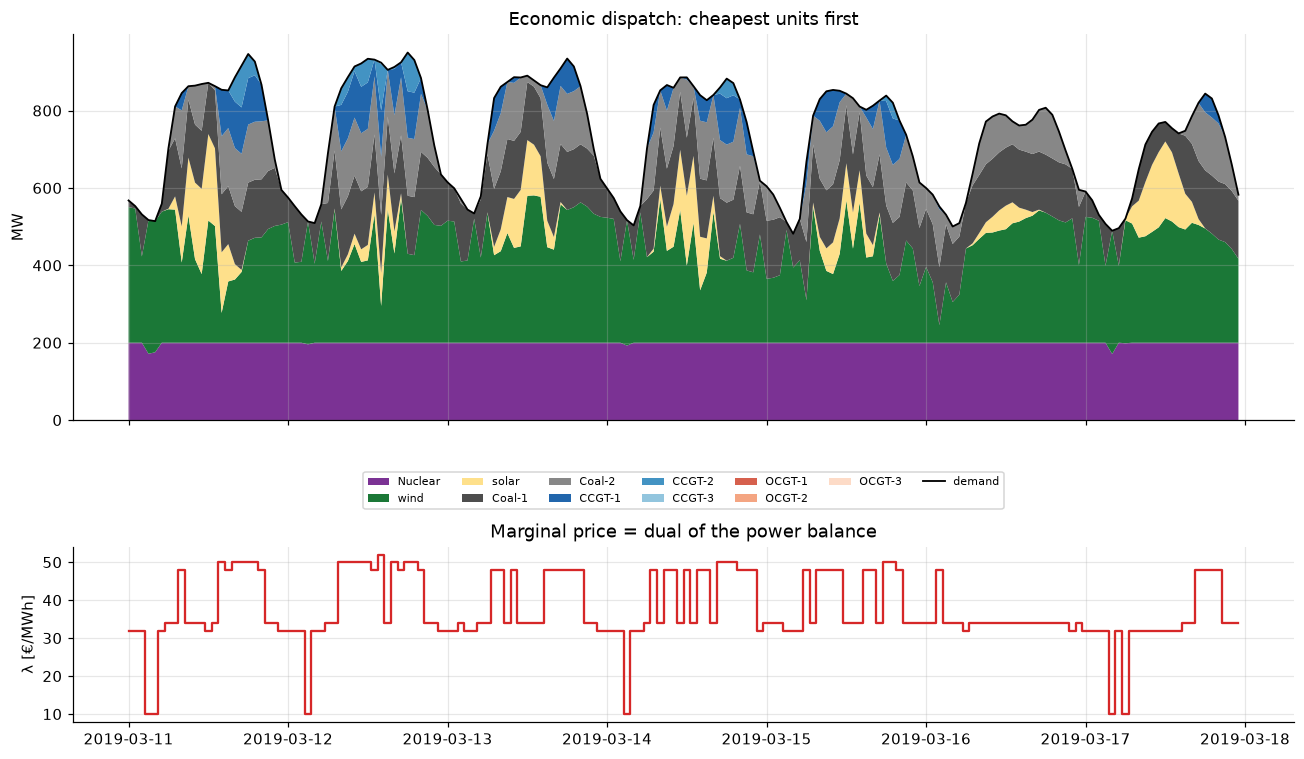

price levels found by the LP (€/MWh): [np.float64(10.0), np.float64(32.0), np.float64(34.0), np.float64(48.0), np.float64(50.0), np.float64(52.0)]
fuel costs of the fleet (€/MWh):      [10, 32, 34, 48, 50, 52, 105, 110, 115]


In [4]:
ed = solve(build(commitment=False), duals=True)
price = pd.Series([ed.dual[ed.balance[t]] for t in T], index=hours)
d_ed = dispatch(ed)

colors = {"Nuclear": "#7b3294", "Coal-1": "#4d4d4d", "Coal-2": "#878787", "CCGT-1": "#2166ac", "CCGT-2": "#4393c3",
          "CCGT-3": "#92c5de", "OCGT-1": "#d6604d", "OCGT-2": "#f4a582", "OCGT-3": "#fddbc7", "wind": "#1b7837", "solar": "#fee08b"}

def stack_plot(d, title, ax):
    cols = ["Nuclear", "wind", "solar"] + [g for g in fleet.index if g != "Nuclear"]
    pos = d[cols].clip(lower=0)
    if "battery" in d:
        pos = pos.assign(**{"battery discharge": d.battery.clip(lower=0)})
    ax.stackplot(d.index, pos.T.values, labels=pos.columns, colors=[colors.get(c, "#e08214") for c in pos.columns], lw=0)
    if "battery" in d:
        ax.fill_between(d.index, 0, d.battery.clip(upper=0), color="#e08214", alpha=0.5, label="battery charge")
    ax.plot(d.index, demand, "k", lw=1.2, label="demand")
    ax.set(title=title, ylabel="MW"); ax.legend(ncol=7, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
stack_plot(d_ed, "Economic dispatch: cheapest units first", ax[0])
ax[1].step(price.index, price.values, where="mid", color="tab:red"); ax[1].set(ylabel="λ [€/MWh]", title="Marginal price = dual of the power balance")
plt.tight_layout(); plt.show()
print("price levels found by the LP (€/MWh):", sorted(set(np.round(price.values, 1))))
print("fuel costs of the fleet (€/MWh):     ", sorted(fleet.fuel.tolist()))

The economic dispatch is cheap and fast, but **physically impossible**: it ramps nuclear and coal to zero and back
within an hour, and runs units below their minimum stable output.

## 4. Unit commitment (MILP): on/off decisions, minimum output, start-up costs

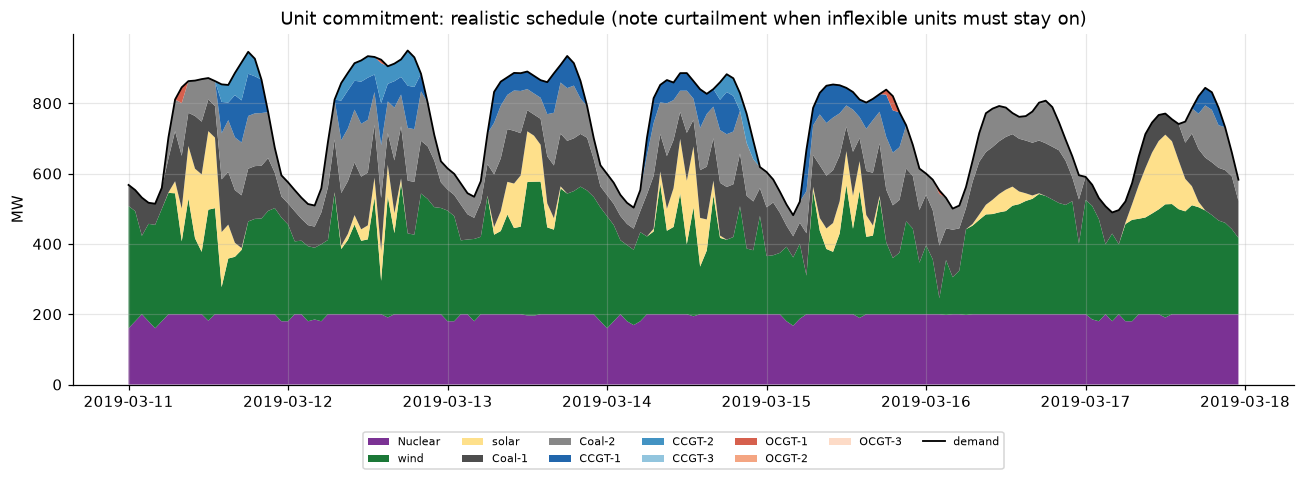

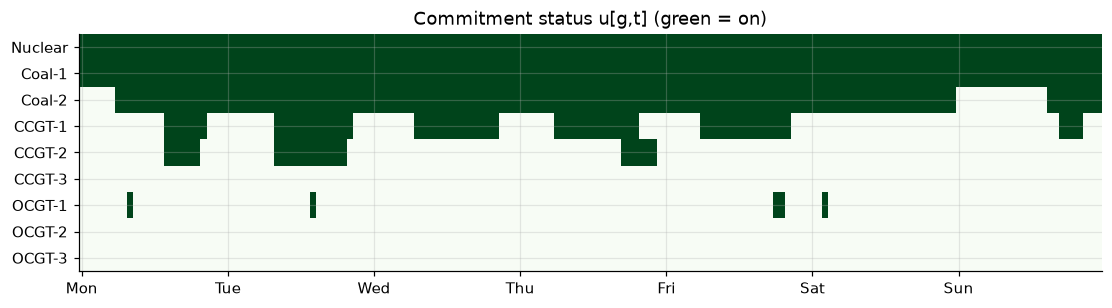

,operating cost [k€],CO2 [kt],renewables curtailed [MWh],load shed [MWh],start-ups,solve time [s]
case,,,,,,
"economic dispatch (LP, unrealistic)",1715.3,33.2,-0.0,0.0,0,0.1
unit commitment (MILP),1852.8,33.8,993.6,0.0,15,7.7


In [5]:
uc = solve(build(commitment=True))
d_uc = dispatch(uc)
fig, ax = plt.subplots(figsize=(12, 4.5))
stack_plot(d_uc, "Unit commitment: realistic schedule (note curtailment when inflexible units must stay on)", ax)
plt.tight_layout(); plt.show()

on = pd.DataFrame({g: [pyo.value(uc.u[g, t]) for t in T] for g in fleet.index}, index=hours).T
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.imshow(on.values, aspect="auto", cmap="Greens", interpolation="nearest")
ax.set(yticks=range(len(on)), yticklabels=on.index, xticks=range(0, 168, 24), xticklabels=[h.strftime("%a") for h in hours[::24]],
       title="Commitment status u[g,t] (green = on)"); plt.show()

rows = [summary(ed, "economic dispatch (LP, unrealistic)"), summary(uc, "unit commitment (MILP)")]
display(pd.DataFrame(rows).set_index("case").round(1))

## 5. Adding a battery: 100 MW / 400 MWh

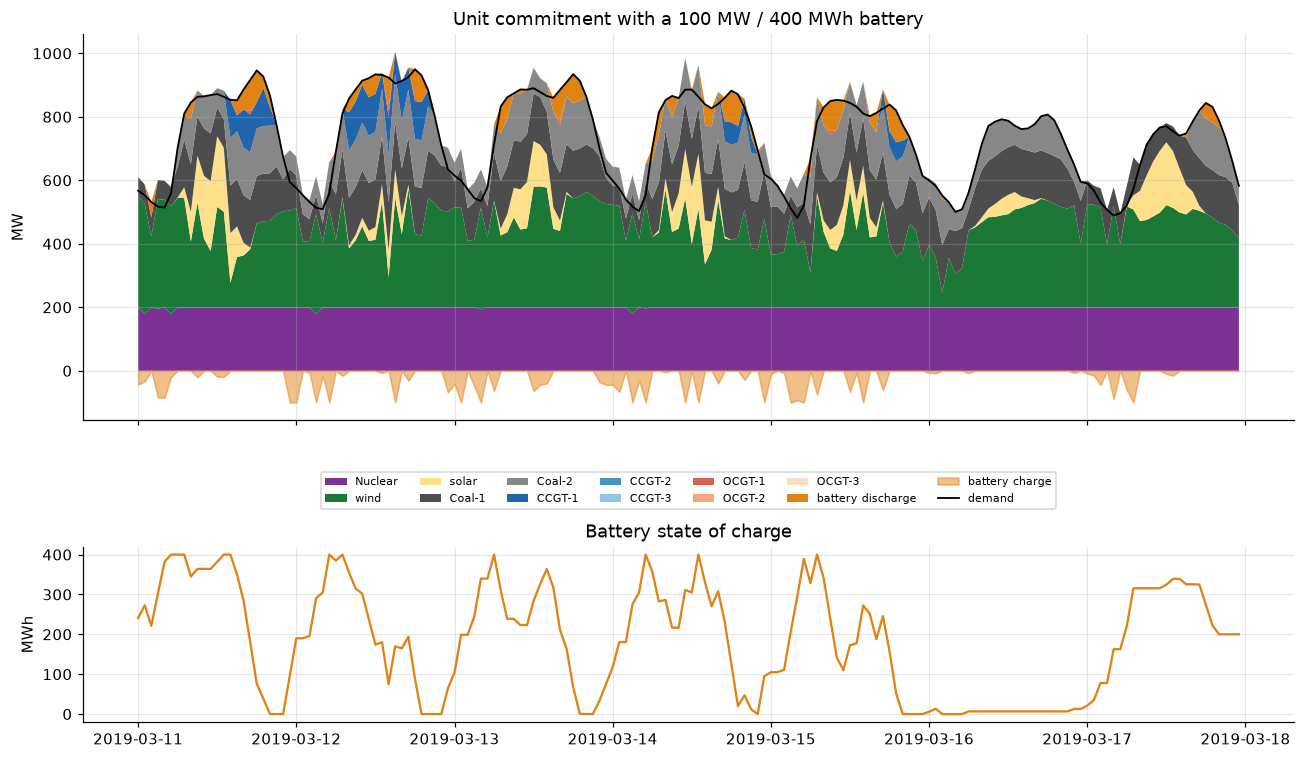

,operating cost [k€],CO2 [kt],renewables curtailed [MWh],load shed [MWh],start-ups,solve time [s]
case,,,,,,
"economic dispatch (LP, unrealistic)",1715.3,33.2,-0.0,0.0,0,0.1
unit commitment (MILP),1852.8,33.8,993.6,0.0,15,7.7
unit commitment + battery,1733.9,35.0,11.8,0.1,10,7.4


In [6]:
BATT = {"power": 100, "energy": 400, "eta": 0.95}
ucb = solve(build(commitment=True, battery=BATT))
d_ucb = dispatch(ucb)
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
stack_plot(d_ucb, "Unit commitment with a 100 MW / 400 MWh battery", ax[0])
ax[1].plot(d_ucb.index, d_ucb.soc, color="#e08214"); ax[1].set(ylabel="MWh", title="Battery state of charge")
plt.tight_layout(); plt.show()
rows.append(summary(ucb, "unit commitment + battery"))
display(pd.DataFrame(rows).set_index("case").round(1))

The battery removes almost all curtailment, reduces start-ups and saves cost, **but CO₂ goes up**. It stores
night-time *coal* power as well as surplus wind, so coal output rises (~+3 000 MWh) while the cleaner but more expensive
gas units run less (~−4 000 MWh). Cheapest is not cleanest: storage follows prices, and without a carbon price
coal is cheaper than gas.

## 6. Cost versus emissions: the Pareto front
Two objectives conflict: cheapest (coal before gas) versus cleanest (gas before coal). The **ε-constraint method** minimises
cost subject to $\text{CO}_2 \le \varepsilon$ for a range of ε between the two extremes. Every point on the curve is
*Pareto-optimal*: emissions cannot be reduced without paying more.

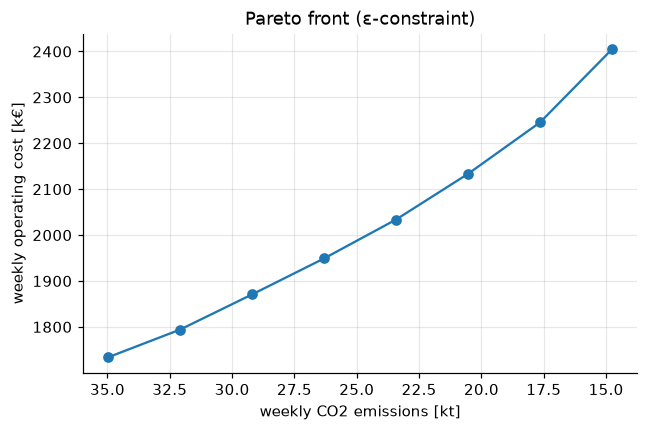

,CO2 [kt],cost [k€],abatement cost [€/t]
0,35.0,1733.9,NaN
1,32.1,1794.2,21.0
2,29.2,1870.8,27.0
3,26.3,1949.2,27.0
4,23.4,2033.9,29.0
5,20.5,2133.5,34.0
6,17.6,2245.5,39.0
7,14.8,2404.9,55.0


In [7]:
e_max = pyo.value(ucb.emis)
cleanest = solve(build(commitment=True, battery=BATT, objective="emissions"))
e_min = pyo.value(cleanest.emis)
pareto = []
for eps in np.linspace(e_max, e_min, 8):
    mm = solve(build(commitment=True, battery=BATT, co2_cap=eps * 1.0001))
    pareto.append({"CO2 [kt]": pyo.value(mm.emis) / 1e3, "cost [k€]": pyo.value(mm.oper_cost) / 1e3})
pareto = pd.DataFrame(pareto)
pareto["abatement cost [€/t]"] = (pareto["cost [k€]"].diff() / -pareto["CO2 [kt]"].diff()).round(0)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(pareto["CO2 [kt]"], pareto["cost [k€]"], "o-")
ax.set(xlabel="weekly CO2 emissions [kt]", ylabel="weekly operating cost [k€]", title="Pareto front (ε-constraint)"); ax.invert_xaxis(); plt.show()
display(pareto.round(1))

The slope of the front is the **marginal abatement cost**: the price per tonne at which it pays to cut emissions further.
A carbon price does the same job through the market: it adds $\pi_{CO_2}\cdot$co2 to each unit's cost and reorders the merit order.

In [8]:
cp_rows = []
for cp in (0, 25, 50, 75, 100, 150):
    mm = solve(build(commitment=True, battery=BATT, carbon_price=cp))
    d = dispatch(mm)
    cp_rows.append({"carbon price [€/t]": cp, "CO2 [kt]": pyo.value(mm.emis) / 1e3,
                    "coal share": d[["Coal-1", "Coal-2"]].sum().sum() / demand.sum(),
                    "gas share": d[[g for g in fleet.index if "GT" in g]].sum().sum() / demand.sum()})
display(pd.DataFrame(cp_rows).set_index("carbon price [€/t]").style.format({"CO2 [kt]": "{:.1f}", "coal share": "{:.0%}", "gas share": "{:.0%}"}))

,CO2 [kt],coal share,gas share
carbon price [€/t],,,
0,35.0,30%,2%
25,31.9,26%,6%
50,15.3,1%,31%
75,15.3,1%,31%
100,15.1,1%,32%
150,14.8,0%,32%


## 7. Sensitivity analysis: how big should the battery be?
Decision support also means asking *what if*. We re-solve the week for several battery sizes (4-hour batteries).

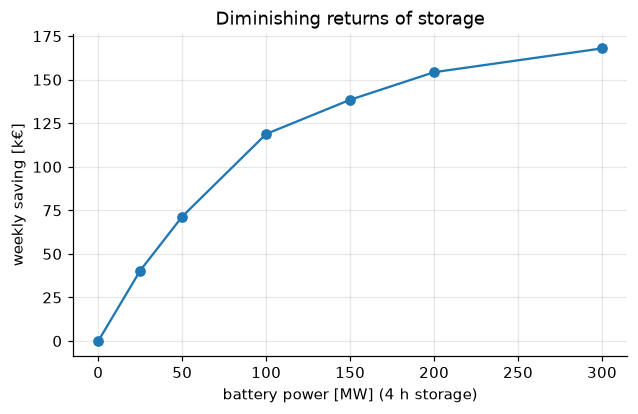

,weekly saving [k€],curtailed [MWh],solve time [s],saving per extra MW [k€/MW]
battery [MW],,,,
0,0.00,993.62,7.66,NaN
25,40.47,546.33,11.24,1.62
50,71.46,240.91,16.15,1.24
100,118.86,11.78,23.00,0.95
150,138.48,-0.00,22.12,0.39
200,154.32,-0.00,15.89,0.32
300,167.98,-0.00,5.95,0.14


In [9]:
sens = []
base_cost = pyo.value(uc.oper_cost)
for mw in (0, 25, 50, 100, 150, 200, 300):
    mm = uc if mw == 0 else solve(build(commitment=True, battery={"power": mw, "energy": 4 * mw}))
    d = dispatch(mm)
    sens.append({"battery [MW]": mw, "weekly saving [k€]": (base_cost - pyo.value(mm.oper_cost)) / 1e3,
                 "curtailed [MWh]": d.curtailed.sum(), "solve time [s]": mm.solve_time})
sens = pd.DataFrame(sens).set_index("battery [MW]")
sens["saving per extra MW [k€/MW]"] = (sens["weekly saving [k€]"].diff() / sens.index.to_series().diff()).round(2)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(sens.index, sens["weekly saving [k€]"], "o-")
ax.set(xlabel="battery power [MW] (4 h storage)", ylabel="weekly saving [k€]", title="Diminishing returns of storage"); plt.show()
display(sens.round(2))

## Key takeaways
* **LP economic dispatch** gives the merit order and prices (duals) but ignores on/off physics.
* **MILP unit commitment** adds minimum output, start-up costs, minimum up/down times and ramps: realistic, at the
  price of binary variables and longer solve times.
* **Storage** shifts cheap (or otherwise curtailed) energy to expensive hours; its value grows with size but with
  diminishing returns, which sensitivity analysis quantifies.
* **Multi-objective**: the ε-constraint method traces the cost–emissions Pareto front; its slope is the abatement cost,
  which a carbon price reproduces through the market.
* Everything here assumes *perfect forecasts*. Notebook 11 (model predictive control) handles forecast errors by
  re-optimising as new information arrives.